# The simulated market

The hedging bot never generates prices itself: it asks a `MarketSource` for the end-of-day
market of each date. `SimulatedSource` is the one used for backtests. This notebook shows what
it produces and checks that it behaves as intended.

Why simulate:

- the same book can be replayed on hundreds of paths, so results come with a dispersion
- the volatility the market *realises* can be set apart from the *implied* one the pricer uses,
  which is how the volatility bet of a hedged option is measured
- a seed makes every path reproducible

1. The model and the dates
2. One path, then many
3. Checks: no drift, realised vols and correlations
4. Realised vs implied volatility
5. Fixings published along the path
6. Limits

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import QuantLib as ql

from cmdty import MarketData, Quote, load_portfolio
from cmdty.market import SimulatedSource, any_exchange_calendar, exchange_calendar
from cmdty.plotting import MUTED, SERIES, price_axis_right, ref_line, titles, use_style

use_style()

## 1. The model and the dates

Each future follows a **driftless geometric Brownian motion** (GBM), the dynamics Black-76
and Kirk assume:

$$
F(t) = F_0 \exp\left(-\tfrac{1}{2}\sigma^2 t + \sigma W(t)\right)
$$

- no drift: a future is a fair bet, $E[F(t)] = F_0$
- the $-\tfrac{1}{2}\sigma^2 t$ term keeps that expectation exact
- the Brownian motions $W$ of the underlyings are correlated through a Cholesky factor of the
  correlation matrix (the same code as the Monte Carlo pricer)

The path moves on **every day either exchange settles** (NYMEX or ICE). Each snapshot is end
of day: the day's settlement is both the forward and that day's published fixing.

In [2]:
start = MarketData(
    today=ql.Date(10, 11, 2026), rate=0.04,
    quotes={"HO": Quote(105.0, 0.30), "BRENT": Quote(75.0, 0.32), "WTI": Quote(71.0, 0.33)},
    correlations={("HO", "BRENT"): 0.95, ("WTI", "BRENT"): 0.97, ("HO", "WTI"): 0.93},
)

calendar = any_exchange_calendar(["NYMEX", "ICE-EU"])
end = ql.Date(15, 7, 2027)

source = SimulatedSource(start, end, calendar, seed=2)
dates = source.dates()
print(f"{len(dates)} dates simulated from {dates[0].ISO()} to {dates[-1].ISO()}")

# checking some specific dates : 
nymex, ice = exchange_calendar("NYMEX"), exchange_calendar("ICE-EU")
for d in (ql.Date(18, 1, 2027), ql.Date(26, 3, 2027), ql.Date(18, 6, 2027)):
    print(f"{d.ISO()}  NYMEX open: {nymex.isBusinessDay(d)!s:<5}  ICE open: {ice.isBusinessDay(d)!s:<5}"
          f"  simulated: {d in dates}")

175 dates simulated from 2026-11-10 to 2027-07-15
2027-01-18  NYMEX open: False  ICE open: True   simulated: True
2027-03-26  NYMEX open: False  ICE open: False  simulated: False
2027-06-18  NYMEX open: False  ICE open: True   simulated: True


Martin Luther King day (18 Jan) and Juneteenth (18 Jun): NYMEX is closed, ICE settles, so the
day is simulated (the Brent put fixes on it). Good Friday: both closed, no settlement.

## 2. One path, then many

                    HO      BRENT        WTI
2026-11-10  105.000000  75.000000  71.000000
2026-11-11  105.299189  75.010048  70.905122
2026-11-12  101.326173  72.823996  69.086542
2026-11-13  100.797287  72.731468  69.051962
2026-11-16   99.253656  72.236478  68.364926


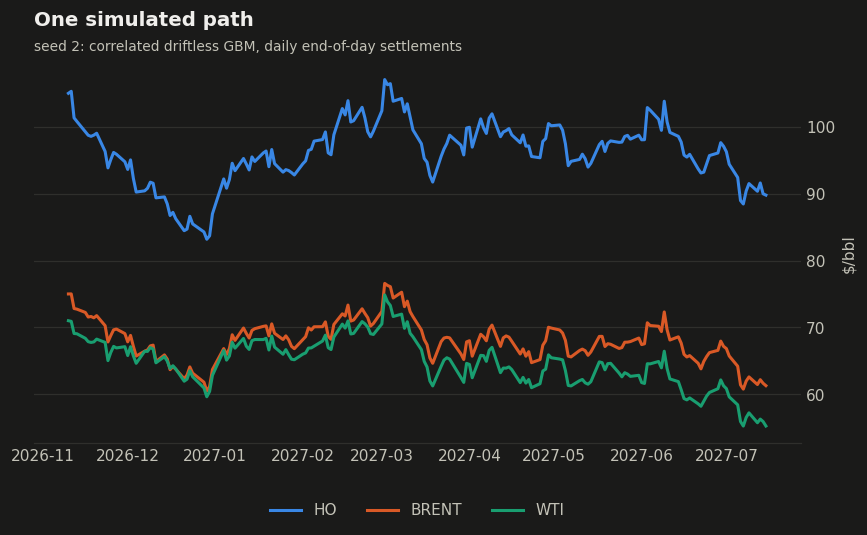

In [3]:
def path_frame(src):
    rows = {d.to_date(): {u: src.snapshot(d).forward(u) for u in src.underlyings} for d in src.dates()}
    frame = pd.DataFrame(rows).T
    frame.index = pd.to_datetime(frame.index)
    return frame

one = path_frame(source)
print(one.head())
fig, ax = plt.subplots(figsize=(9, 4.5))
for (u, s), color in zip(one.items(), SERIES):
    ax.plot(one.index, s, color=color, label=u)
price_axis_right(ax)
ax.set(ylabel="$/bbl")
titles(ax, "One simulated path", "seed 2: correlated driftless GBM, daily end-of-day settlements")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False)
plt.show()

                  0          1          2          3          4          5    \
2026-11-10  75.000000  75.000000  75.000000  75.000000  75.000000  75.000000   
2026-11-11  75.087759  75.727692  75.010048  76.436235  74.147971  73.527609   
2026-11-12  74.992258  74.515171  72.823996  75.559076  74.278850  74.451838   
2026-11-13  76.933949  74.095715  72.731468  73.070105  73.592471  73.487399   
2026-11-16  73.847685  74.686608  72.236478  80.208341  74.211380  77.031896   

                  6          7          8          9    ...        290  \
2026-11-10  75.000000  75.000000  75.000000  75.000000  ...  75.000000   
2026-11-11  76.968500  75.108210  72.435585  74.131693  ...  75.201695   
2026-11-12  77.197144  73.865101  71.155493  75.348437  ...  76.317752   
2026-11-13  78.606574  74.445447  70.398314  75.955317  ...  76.617757   
2026-11-16  79.905674  73.477739  73.631445  72.787465  ...  75.752753   

                  291        292        293        294        295        2

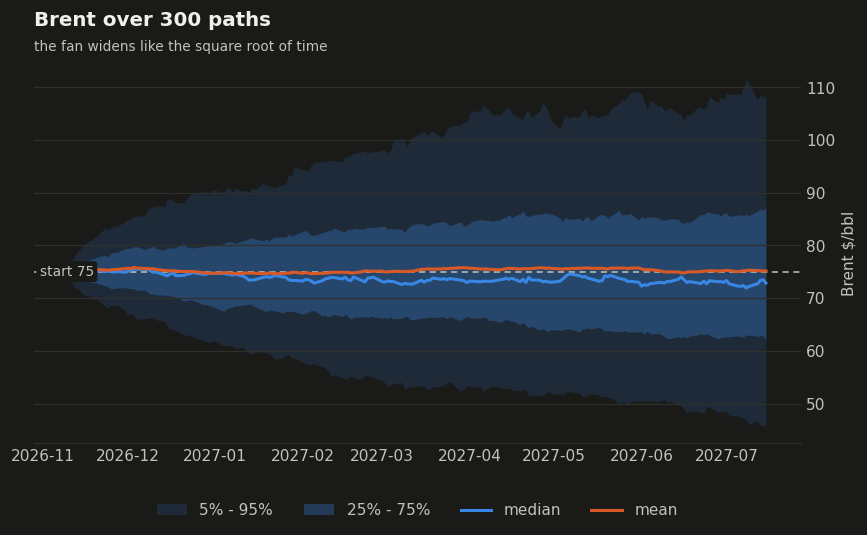

In [4]:
n_paths = 300
brent = pd.DataFrame({s: path_frame(SimulatedSource(start, end, calendar, seed=s))["BRENT"]
                      for s in range(n_paths)})
print(brent.head())
q = brent.quantile([0.05, 0.25, 0.5, 0.75, 0.95], axis=1).T
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.fill_between(q.index, q[0.05], q[0.95], color=SERIES[0], alpha=0.15, linewidth=0, label="5% - 95%")
ax.fill_between(q.index, q[0.25], q[0.75], color=SERIES[0], alpha=0.30, linewidth=0, label="25% - 75%")
ax.plot(q.index, q[0.5], color=SERIES[0], label="median")
ax.plot(brent.index, brent.mean(axis=1), color=SERIES[1], label="mean")
ref_line(ax, 75.0, "start 75")
price_axis_right(ax)
ax.set(ylabel="Brent $/bbl")
titles(ax, f"Brent over {n_paths} paths", "the fan widens like the square root of time")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False)
plt.show()

The **mean** stays at 75: no drift. The **median** slowly falls below it: a lognormal price is
skewed, a few paths go far up, more paths end a bit lower.

## 3. Checks

Over the 300 paths, from the daily log-returns:

- the mean of the final price should be the starting forward (no drift)
- the realised vol should be the input vol
- the correlation of the daily returns should be the input correlation

In [5]:
paths = {s: path_frame(SimulatedSource(start, end, calendar, seed=s)) for s in range(n_paths)}
returns = pd.concat([np.log(p).diff().dropna() for p in paths.values()])
years = np.mean(np.diff([ql.Actual365Fixed().yearFraction(start.today, d) for d in dates]))

finals = pd.DataFrame([p.iloc[-1] for p in paths.values()])
checks = pd.DataFrame({
    "start forward": {u: start.forward(u) for u in finals},
    "mean final": finals.mean(),
    "input vol": {u: start.vol(u) for u in finals},
    "realised vol": returns.std() / np.sqrt(years),
})
checks.round(3)

,start forward,mean final,input vol,realised vol
HO,105.0,105.123,0.30,0.30
BRENT,75.0,75.135,0.32,0.32
WTI,71.0,71.559,0.33,0.33


In [6]:
corr_in = pd.DataFrame([[start.corr(a, b) for b in returns] for a in returns],
                       index=returns.columns, columns=returns.columns)
pd.concat({"input": corr_in, "realised": returns.corr()}, axis=1).round(3)

input             realised            
         HO BRENT   WTI       HO BRENT   WTI
HO     1.00  0.95  0.93     1.00  0.95  0.93
BRENT  0.95  1.00  0.97     0.95  1.00  0.97
WTI    0.93  0.97  1.00     0.93  0.97  1.00

Means, vols and correlations come back as set, within the noise of 300 paths. The realised vol
is computed per step of time actually elapsed (weekends make some steps three days long).

## 4. Realised vs implied volatility

The source keeps two vols apart:

- the **implied** vol in each snapshot, what the pricer sees and prices with
- the **realised** vol that moves the path

Below, the same seed with the market realising 60%, 100% and 140% of the implied vols. The
snapshots carry the same implied vol in all three cases.

realised 60%: Brent implied vol in the last snapshot = 0.32
realised 100%: Brent implied vol in the last snapshot = 0.32


realised 140%: Brent implied vol in the last snapshot = 0.32


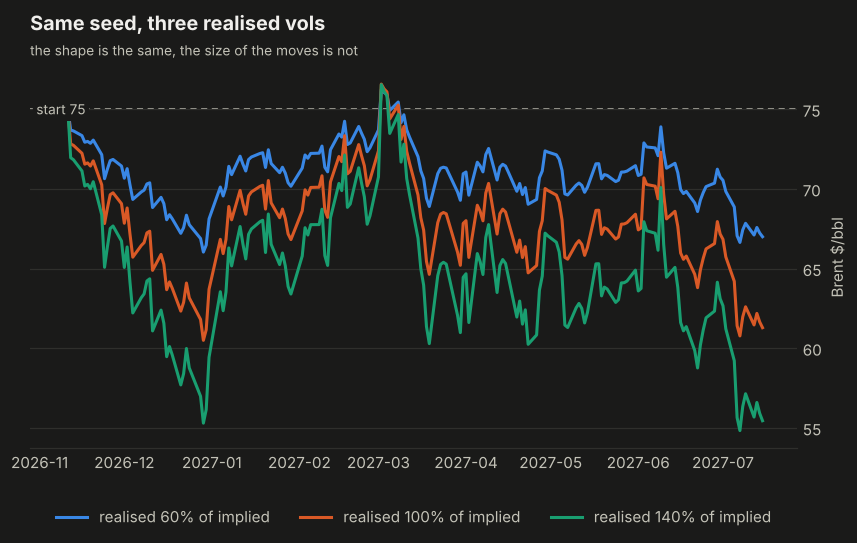

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for scale, color in zip((0.6, 1.0, 1.4), SERIES):
    vols = {u: start.vol(u) * scale for u in start.quotes}
    src = SimulatedSource(start, end, calendar, realized_vol=vols, seed=2)
    p = path_frame(src)
    ax.plot(p.index, p["BRENT"], color=color, label=f"realised {scale:.0%} of implied")
    print(f"realised {scale:.0%}: Brent implied vol in the last snapshot = "
          f"{src.snapshot(src.dates()[-1]).vol('BRENT'):.2f}")
ref_line(ax, 75.0, "start 75")
price_axis_right(ax)
ax.set(ylabel="Brent $/bbl")
titles(ax, "Same seed, three realised vols", "the shape is the same, the size of the moves is not")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False)
plt.show()

This is what notebook 03 uses to measure the volatility bet: sell the option at the implied
vol, let the market realise more or less, and look at the hedged P&L.

## 5. Fixings published along the path

Each snapshot carries the settlements published so far. Here, the January Brent put of the
example book: how much of its average is known on a few dates of its pricing month.

In [8]:
book = load_portfolio("../portfolios/example_book.yaml")
put = book.trade("APO-001").instrument
fixing_dates = put.schedule.fixing_dates()

rows = []
for d in (ql.Date(4, 1, 2027), ql.Date(15, 1, 2027), ql.Date(29, 1, 2027)):
    m = source.snapshot(d)
    known = [f for f in fixing_dates if f in m.fixings["BRENT"]]
    rows.append({"date": d.ISO(), "fixings known": f"{len(known)} / {len(fixing_dates)}",
                 "average so far": np.mean([m.fixing("BRENT", f) for f in known]),
                 "forward today": m.forward("BRENT")})
pd.DataFrame(rows).set_index("date").round(2)

,fixings known,average so far,forward today
date,,,
2027-01-04,1 / 20,66.83,66.83
2027-01-15,10 / 20,68.33,69.81
2027-01-29,20 / 20,68.56,66.82


On the last day of January every fixing is known: the payoff is certain and the deltas of
the trade are zero, which is why its hedge is closed that day in notebook 03.

## 6. Limits

- **One forward per underlying**: all contract months move together, no curve shape and no
  time-spread risk.
- **GBM only**: no jumps, no fat tails, no mean reversion, no volatility clustering. Real
  oil prices have all four.
- **Constant implied vol and correlation**: vega and correlation P&L are zero in the backtests.
- **Daily steps at settlement**: nothing happens between two end-of-day snapshots.

A historical source (real settlements) would lift most of these; it follows the same
`dates()` / `snapshot(date)` interface, so the bot would not change.